In [1]:
# 策略：ARMA 收益率预测（代码见 autotrader/research/forecast.py）
#       用过去的日收益率预测明天的日收益率。前 70%（约 7 年）训练：在 ARMA(0~2, 0~2) 中按 AIC 选阶并估计参数；
#       后 30%（约 3 年）测试：参数固定，每天收盘后只用当天及以前的数据预测明天。
#       交易规则（只用于检验预测，不计手续费）：预测明天涨 → 持有一天；预测跌 → 空仓。
#       对比基准：方向上“每天都猜涨”；收益上“一直持有”，以及最初的均线策略：
#         收盘时 10 日均线 > 30 日均线 → 第二天全仓持有；否则 → 第二天空仓（全进全出，不计手续费）。
# 买入：TSLA（特斯拉）、AAPL（苹果）、MSFT（微软）、GOOGL（谷歌 A 类股）、KO（可口可乐），各自独立预测和计算；
#       价格用复权日线（分红、拆股已调整），最近 10 年。
#
# 表：每只股票的模型和测试期指标（本单元格做全部计算，后面的图都依赖它）。
import sys
sys.path.insert(0, "..")  # 让 notebook 能 import 项目里的 autotrader
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from autotrader.research.forecast import load_prices, daily_returns, arma_forecast, evaluate

symbols = ["TSLA", "AAPL", "MSFT", "GOOGL", "KO"]
tables, rows = {}, {}
for s in symbols:
    close = load_prices(s)["close"].loc["2016-10-24":]  # 固定为当初研究用的 10 年（数据文件后来变长了）
    table, info = arma_forecast(daily_returns(close))
    # 均线策略：前一天收盘时 10 日均线 > 30 日均线，当天就持有（和 ARMA 规则一样按收盘到收盘计算收益）
    sma_signal = (close.rolling(10).mean() > close.rolling(30).mean()).shift(1)
    table["sma_long"] = sma_signal.reindex(table.index).astype(bool)
    tables[s] = table
    rows[s] = {"模型": info["order"], "训练期自相关p值": info["ljung_box_p"], **evaluate(table, info["train_mean"]),
               "均线策略收益": float(np.exp(table["actual"].where(table["sma_long"], 0).sum() / 100) - 1)}

summary = pd.DataFrame(rows).T
print("训练期", info["train"], " 测试期", info["test"])
summary.style.format({
    "训练期自相关p值": "{:.2g}", "方向准确率": "{:.1%}", "基准：总猜涨": "{:.1%}", "样本外R²": "{:.2%}",
    "预测与实际相关": "{:.3f}", "预测看涨天数": "{:.0%}", "规则累计收益": "{:.0%}", "一直持有收益": "{:.0%}", "均线策略收益": "{:.0%}",
})


训练期 2016-10-25 ~ 2023-10-17  测试期 2023-10-18 ~ 2026-10-19


,模型,训练期自相关p值,方向准确率,基准：总猜涨,样本外R²,预测与实际相关,预测看涨天数,规则累计收益,一直持有收益,均线策略收益
TSLA,"ARMA(2,2)",0.13,49.9%,50.6%,-0.84%,0.010,66%,35%,44%,47%
AAPL,"ARMA(2,2)",2.4e-13,48.7%,54.2%,-3.61%,-0.055,74%,25%,96%,21%
MSFT,"ARMA(0,1)",2.1e-28,52.7%,53.7%,-4.61%,-0.023,69%,57%,64%,41%
GOOGL,"ARMA(0,1)",7e-08,50.7%,54.4%,-0.93%,-0.017,69%,74%,149%,99%
KO,"ARMA(2,2)",1.1e-11,49.5%,52.6%,-1.89%,-0.021,60%,41%,88%,49%


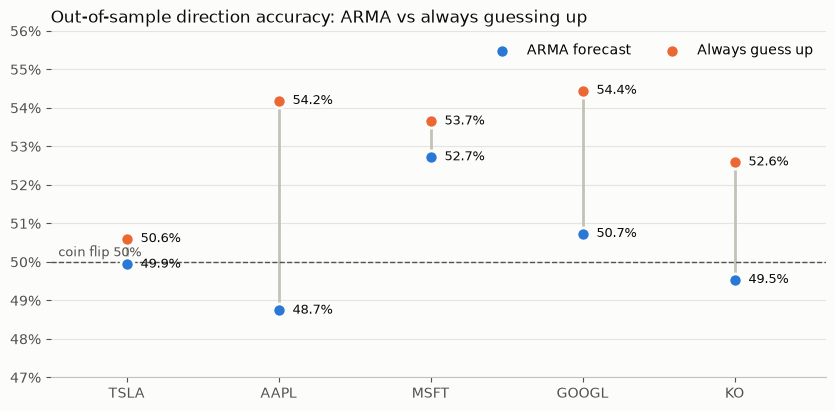

In [2]:
# 策略：ARMA 收益率预测（代码见 autotrader/research/forecast.py）
#       用过去的日收益率预测明天的日收益率。前 70%（约 7 年）训练：在 ARMA(0~2, 0~2) 中按 AIC 选阶并估计参数；
#       后 30%（约 3 年）测试：参数固定，每天收盘后只用当天及以前的数据预测明天。
#       交易规则（只用于检验预测，不计手续费）：预测明天涨 → 持有一天；预测跌 → 空仓。
#       对比基准：方向上“每天都猜涨”；收益上“一直持有”，以及最初的均线策略：
#         收盘时 10 日均线 > 30 日均线 → 第二天全仓持有；否则 → 第二天空仓（全进全出，不计手续费）。
# 买入：TSLA（特斯拉）、AAPL（苹果）、MSFT（微软）、GOOGL（谷歌 A 类股）、KO（可口可乐），各自独立预测和计算；
#       价格用复权日线（分红、拆股已调整），最近 10 年。
#
# 图：测试期的方向准确率（预测涨跌猜对的比例）vs 每天都猜涨的准确率。
#     模型的柱子要明显高于基准才算有用；50% 相当于抛硬币。

def clean(ax):
    """统一的图表样式：浅色背景、只留横向网格线、去掉多余边框。"""
    ax.set_facecolor("#fcfcfb")
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.tick_params(colors="#52514e")
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")

x = list(range(len(symbols)))
model = summary["方向准确率"].astype(float) * 100
base = summary["基准：总猜涨"].astype(float) * 100

fig, ax = plt.subplots(figsize=(10, 4.5), facecolor="#fcfcfb")
ax.vlines(x, model, base, color="#c3c2b7", linewidth=2)  # 灰线 = 模型和基准的差距
for values, name, color in [(model, "ARMA forecast", "#2a78d6"), (base, "Always guess up", "#eb6834")]:
    ax.scatter(x, values, s=90, color=color, edgecolor="#fcfcfb", linewidth=2, zorder=3, label=name)
    for i, v in zip(x, values):
        ax.annotate(f"{v:.1f}%", (i, v), xytext=(10, 0), textcoords="offset points",
                    va="center", fontsize=9, color="#0b0b0b")
ax.axhline(50, color="#52514e", linewidth=1, linestyle="--")
ax.annotate("coin flip 50%", (-0.45, 50), xytext=(0, 4), textcoords="offset points", fontsize=9, color="#52514e")
ax.set_xticks(x, symbols)
ax.set_xlim(-0.5, len(symbols) - 0.4)
ax.set_ylim(47, 56)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
ax.set_title("Out-of-sample direction accuracy: ARMA vs always guessing up", loc="left", color="#0b0b0b")
clean(ax)
ax.legend(loc="upper right", frameon=False, ncol=2)
plt.show()


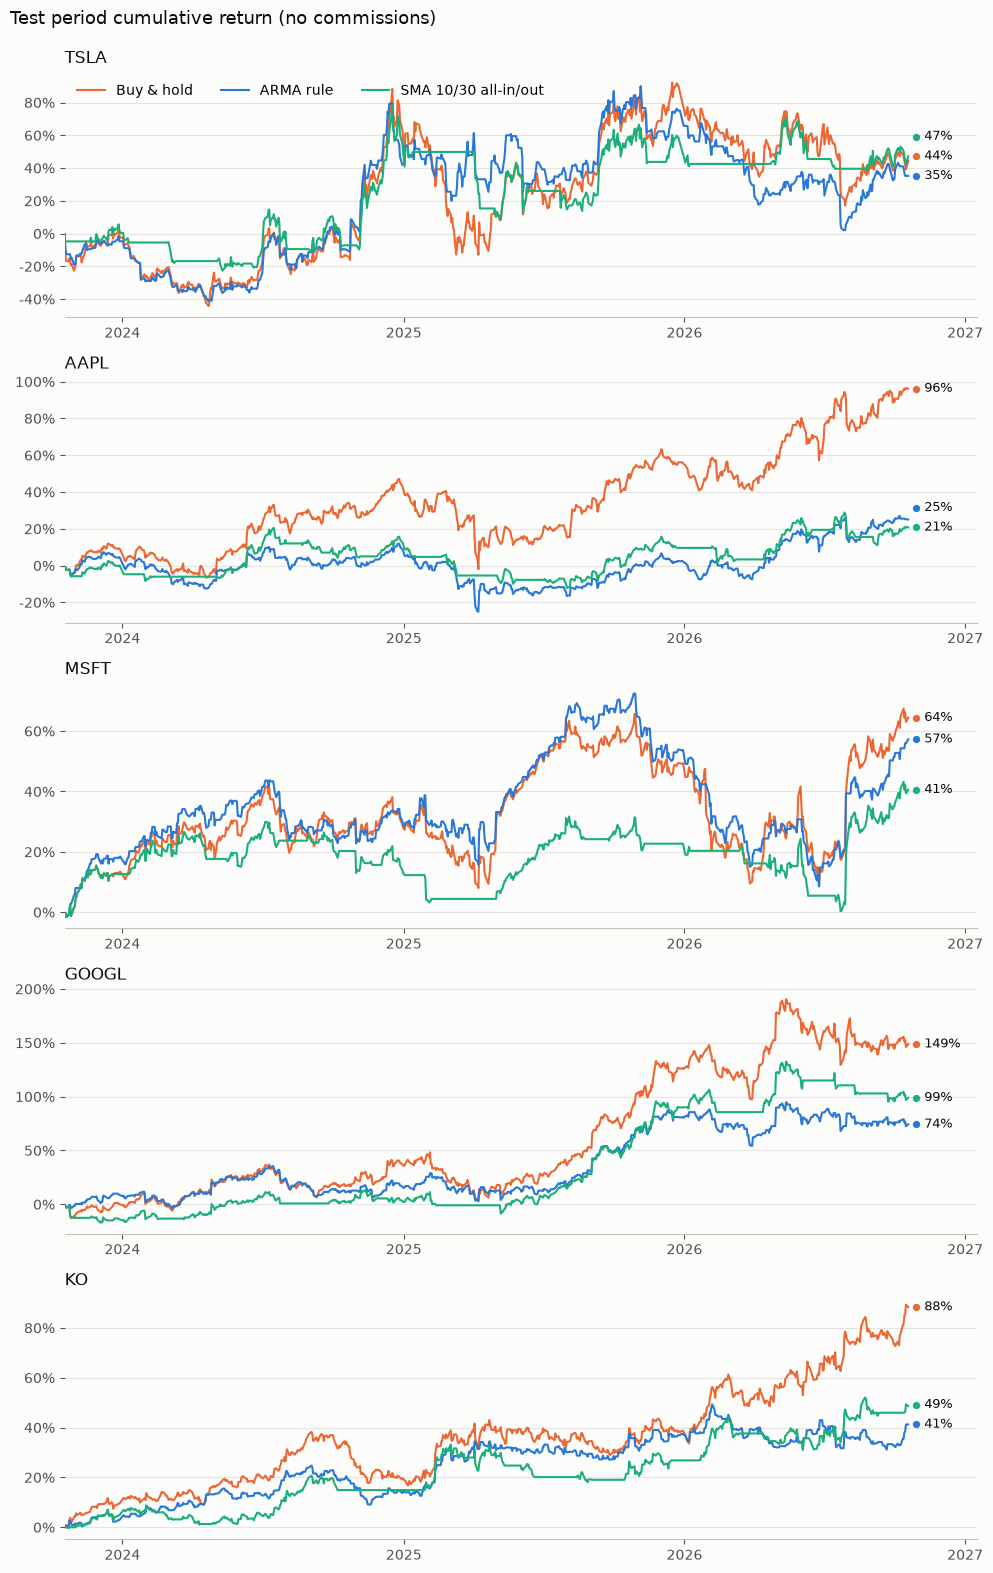

In [3]:
# 策略：ARMA 收益率预测（代码见 autotrader/research/forecast.py）
#       用过去的日收益率预测明天的日收益率。前 70%（约 7 年）训练：在 ARMA(0~2, 0~2) 中按 AIC 选阶并估计参数；
#       后 30%（约 3 年）测试：参数固定，每天收盘后只用当天及以前的数据预测明天。
#       交易规则（只用于检验预测，不计手续费）：预测明天涨 → 持有一天；预测跌 → 空仓。
#       对比基准：方向上“每天都猜涨”；收益上“一直持有”，以及最初的均线策略：
#         收盘时 10 日均线 > 30 日均线 → 第二天全仓持有；否则 → 第二天空仓（全进全出，不计手续费）。
# 买入：TSLA（特斯拉）、AAPL（苹果）、MSFT（微软）、GOOGL（谷歌 A 类股）、KO（可口可乐），各自独立预测和计算；
#       价格用复权日线（分红、拆股已调整），最近 10 年。
#
# 图：测试期累计收益。蓝线 = 按 ARMA 预测进出（预测涨才持有），橙线 = 一直持有，
#     绿线 = 10/30 日均线全进全出。均不计手续费。

def clean(ax):
    """统一的图表样式：浅色背景、只留横向网格线、去掉多余边框。"""
    ax.set_facecolor("#fcfcfb")
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.tick_params(colors="#52514e")
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")

import numpy as np

# 每只股票一行，共用时间轴；纵轴各自独立（各股票涨幅差别很大）
fig, axes = plt.subplots(len(symbols), 1, figsize=(10, 3.2 * len(symbols)), facecolor="#fcfcfb", sharex=True)
lines = [("Buy & hold", "#eb6834"), ("ARMA rule", "#2a78d6"), ("SMA 10/30 all-in/out", "#1baf7a")]
for ax, s in zip(axes, symbols):
    t = tables[s]
    curves = [  # 三条累计收益曲线（%），顺序和 lines 一致
        (np.exp(t["actual"].cumsum() / 100) - 1) * 100,                                # 一直持有
        (np.exp(t["actual"].where(t["predicted"] > 0, 0).cumsum() / 100) - 1) * 100,   # ARMA：预测涨才持有
        (np.exp(t["actual"].where(t["sma_long"], 0).cumsum() / 100) - 1) * 100,        # 均线全进全出
    ]
    for curve, (name, color) in zip(curves, lines):
        ax.plot(t.index, curve, color=color, linewidth=1.5, label=name)
    ax.set_title(s, loc="left", color="#0b0b0b", fontsize=12)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0f}%")
    ax.xaxis.set_major_locator(plt.matplotlib.dates.YearLocator())
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%Y"))
    clean(ax)
    ax.tick_params(labelbottom=True)  # 每一行都显示年份
    ax.set_xlim(t.index[0], t.index[-1] + pd.Timedelta(days=90))  # 右侧留白放末端标签

    # 线的末端标出最终收益：彩色圆点表示是哪条线；数字太近时往上错开，避免重叠
    low, high = ax.get_ylim()
    gap = (high - low) * 0.08
    x = t.index[-1] + pd.Timedelta(days=10)
    y_prev = None
    for value, color in sorted((curve.iloc[-1], color) for curve, (_, color) in zip(curves, lines)):
        y = value if y_prev is None else max(value, y_prev + gap)
        y_prev = y
        ax.scatter([x], [y], s=18, color=color, zorder=3)
        ax.annotate(f"{value:.0f}%", (x, y), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color="#0b0b0b")
    ax.set_ylim(low, max(high, y_prev + gap / 2))

axes[0].legend(loc="upper left", frameon=False, ncol=3)
fig.suptitle("Test period cumulative return (no commissions)", x=0.01, ha="left", color="#0b0b0b", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.985))  # 给总标题留出空间
plt.show()
